<a href="https://colab.research.google.com/github/ritesh23r/MNIST-Perceptron-ANN-CNN-Comparison/blob/main/MNIST_Perceptron_vs_ANN_vs_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical

In [4]:
df = pd.read_csv('mnist_train.csv')
df_test = pd.read_csv('mnist_test.csv')

In [5]:
df.shape

(60000, 785)

In [6]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [8]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [9]:
X_train = df.drop('label', axis=1).values
X_test = df_test.drop('label', axis=1).values
y_train = df['label'].values
y_test = df_test['label'].values

In [10]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [11]:
X_train_img = X_train.reshape(-1, 28 , 28)
X_test_img = X_test.reshape(-1, 28 , 28)

In [ ]:
X_train_img

In [12]:
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

In [13]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation='softmax')
]
)

In [14]:
perceptron.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
history_per = perceptron.fit(X_train_img, y_train_cat, epochs=10 , batch_size=32,
               validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8768 - loss: 0.4719 - val_accuracy: 0.9151 - val_loss: 0.3043
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9151 - loss: 0.3037 - val_accuracy: 0.9220 - val_loss: 0.2784
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9206 - loss: 0.2833 - val_accuracy: 0.9251 - val_loss: 0.2723
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9241 - loss: 0.2731 - val_accuracy: 0.9226 - val_loss: 0.2750
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9252 - loss: 0.2670 - val_accuracy: 0.9272 - val_loss: 0.2650
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9273 - loss: 0.2621 - val_accuracy: 0.9251 - val_loss: 0.2665
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9283 - loss: 0.2584 - val_accuracy: 0.9270 - val_loss: 0.2648
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9294 - loss: 0.2554 - 

In [16]:
acc_parcp = perceptron.evaluate(X_test_img, y_test_cat,verbose=0)[1]
acc_parcp

0.9240999817848206

In [17]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [18]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [19]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=9, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9290 - loss: 0.2412 - val_accuracy: 0.9664 - val_loss: 0.1092
Epoch 2/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9690 - loss: 0.0998 - val_accuracy: 0.9737 - val_loss: 0.0856
Epoch 3/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9783 - loss: 0.0695 - val_accuracy: 0.9752 - val_loss: 0.0860
Epoch 4/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9829 - loss: 0.0539 - val_accuracy: 0.9754 - val_loss: 0.0796
Epoch 5/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9862 - loss: 0.0420 - val_accuracy: 0.9735 - val_loss: 0.0903
Epoch 6/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9891 - loss: 0.0331 - val_accuracy: 0.9731 - val_loss: 0.0868
Epoch 7/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9908 - loss: 0.0281 - val_accuracy: 0.9784 - val_loss: 0.0777
Epoch 8/9
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9922 - loss: 0.0234 - 

In [20]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]
acc_ann

0.9743000268936157

In [21]:
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [22]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [23]:
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [24]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=10, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 70s 36ms/step - accuracy: 0.9372 - loss: 0.2071 - val_accuracy: 0.9845 - val_loss: 0.0470
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 94s 43ms/step - accuracy: 0.9770 - loss: 0.0773 - val_accuracy: 0.9875 - val_loss: 0.0339
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 35ms/step - accuracy: 0.9827 - loss: 0.0570 - val_accuracy: 0.9894 - val_loss: 0.0298
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 36ms/step - accuracy: 0.9871 - loss: 0.0442 - val_accuracy: 0.9912 - val_loss: 0.0252
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 36ms/step - accuracy: 0.9881 - loss: 0.0379 - val_accuracy: 0.9918 - val_loss: 0.0252
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9897 - loss: 0.0332 - val_accuracy: 0.9926 - val_loss: 0.0249
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9912 - loss: 0.0284 - val_accuracy: 0.9919 - val_loss: 0.0274
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9920 -

In [25]:
def plot_traning(history, title):
  plt.figure(figsize=(12,4)),
  plt.subplot(1,2,1)
  plt.plot(history.history['accuracy'], label= "train"),
  plt.plot(history.history['val_accuracy'], label = "validation"),
  plt.legend()
  plt.title(f'Accuracy {title}')


  plt.subplot(1,2,2)
  plt.plot(history.history['loss'], label= "train"),
  plt.plot(history.history['val_loss'], label = "validation"),
  plt.legend()
  plt.title(f'{title} loss')
  plt.show()

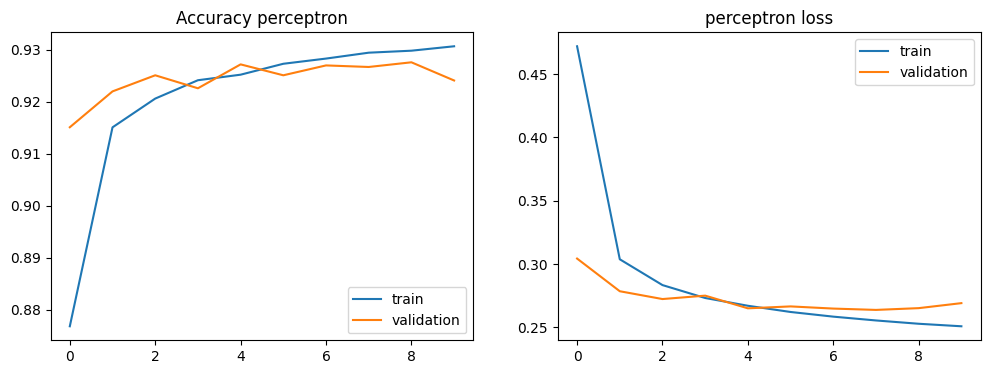

In [26]:
plot_traning(history_per, "perceptron")

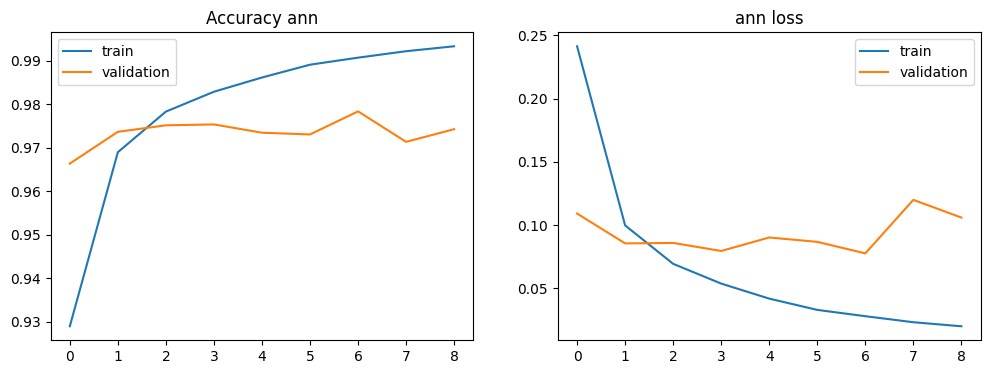

In [27]:
plot_traning(history_ann, "ann")

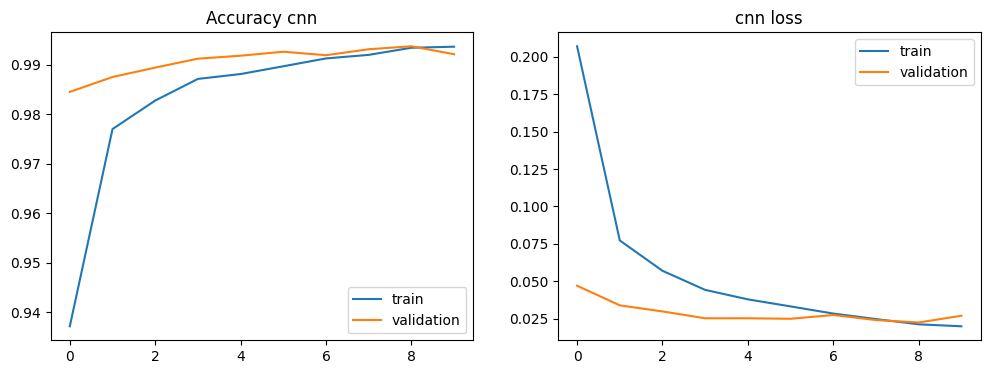

In [28]:
plot_traning(history_cnn, "cnn")

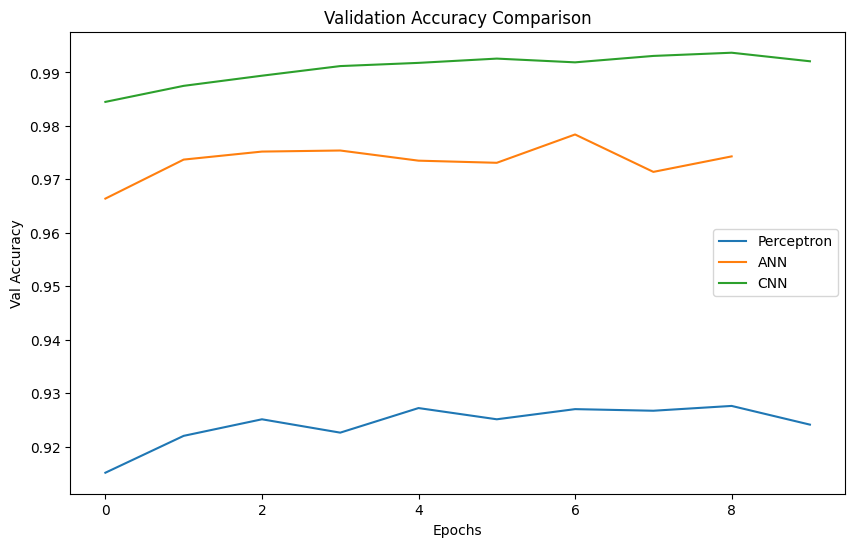

In [29]:
plt.figure(figsize=(10,6))
plt.plot(history_per.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()


In [30]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


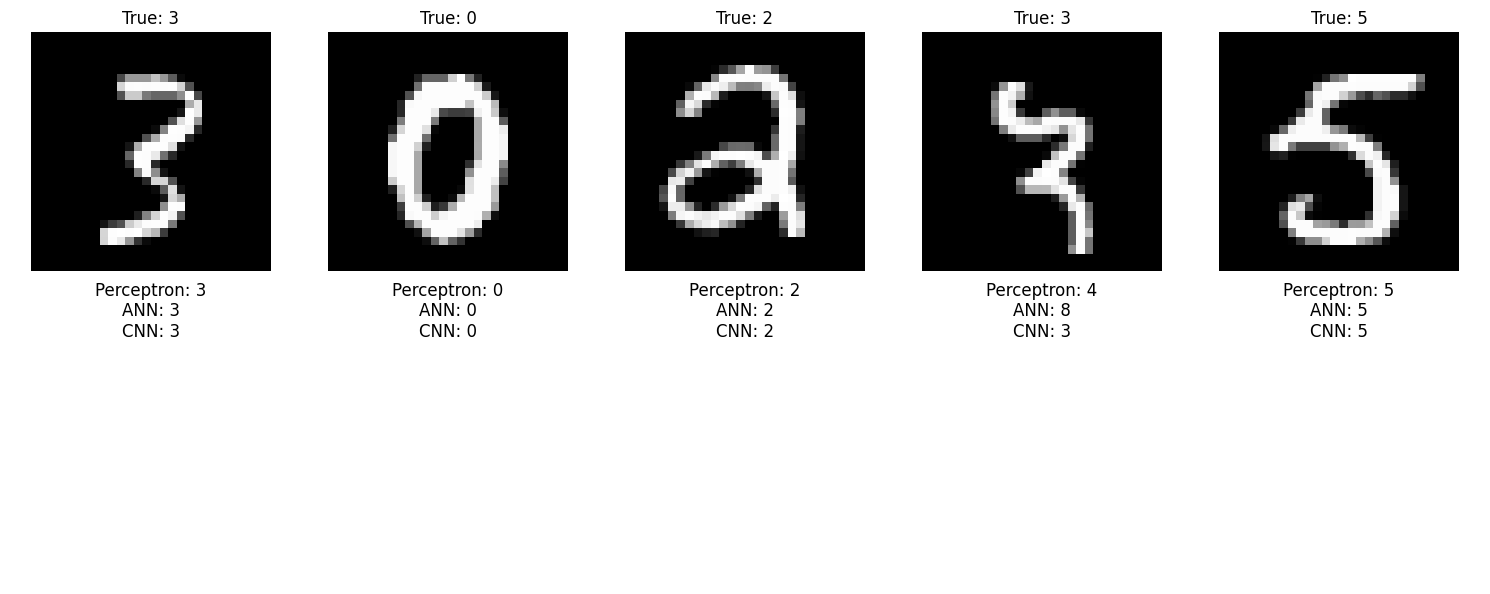

In [76]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


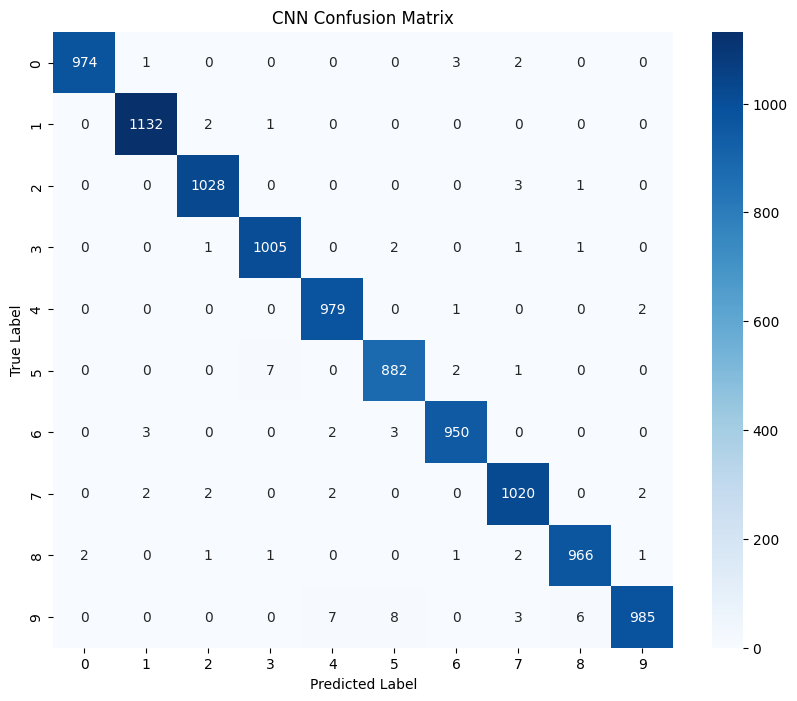

In [32]:
y_pred_cnn = cnn.predict(X_test_cnn)
y_pred_classes_cnn = np.argmax(y_pred_cnn, axis=1)

cm_cnn = confusion_matrix(y_test, y_pred_classes_cnn)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [33]:
# Evaluate all three models on the test set
loss_per, acc_per = perceptron.evaluate(X_test_img, y_test_cat, verbose=0)
loss_ann, acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)
loss_cnn, acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)

# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['Perceptron', 'ANN', 'CNN'],
    'Test Loss': [loss_per, loss_ann, loss_cnn],
    'Test Accuracy': [acc_per, acc_ann, acc_cnn]
})

# Format and display the dataframe
comparison_df['Test Accuracy'] = comparison_df['Test Accuracy'].map('{:.2%}'.format)
comparison_df['Test Loss'] = comparison_df['Test Loss'].map('{:.4f}'.format)
print(comparison_df.to_string(index=False))

     Model Test Loss Test Accuracy
Perceptron    0.2690        92.41%
       ANN    0.1060        97.43%
       CNN    0.0269        99.21%


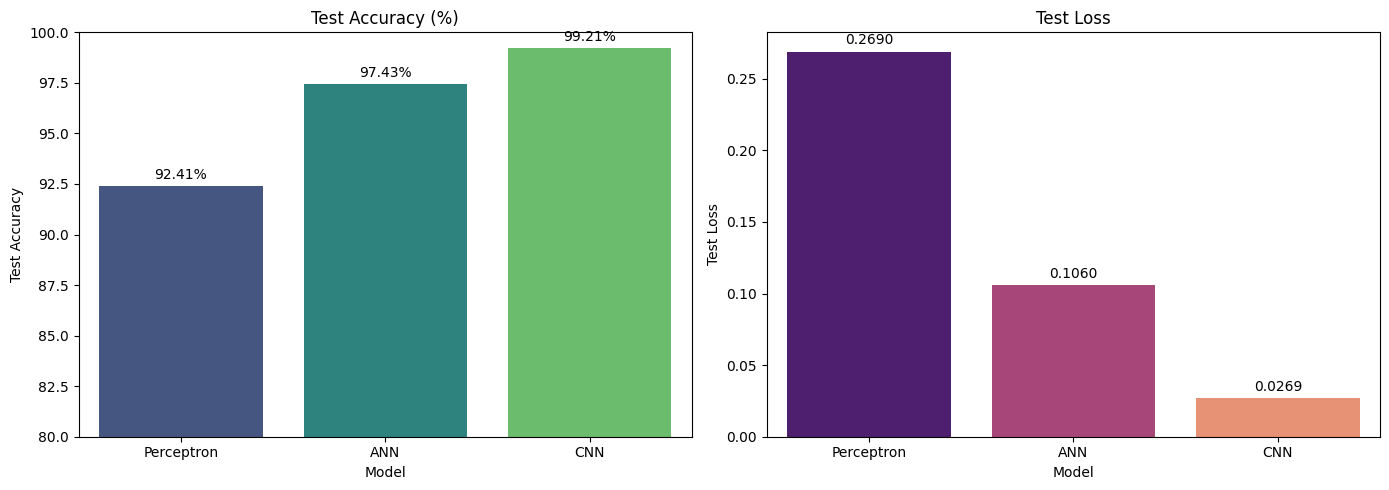

In [34]:
# Visualizing the final performance comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
sns.barplot(x='Model', y=comparison_df['Test Accuracy'].str.rstrip('%').astype('float'), data=comparison_df, ax=axes[0], palette='viridis')
axes[0].set_title('Test Accuracy (%)')
axes[0].set_ylim(80, 100)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

# Loss comparison
sns.barplot(x='Model', y=comparison_df['Test Loss'].astype('float'), data=comparison_df, ax=axes[1], palette='magma')
axes[1].set_title('Test Loss')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout()
plt.show()